

# Deep Learning Homework — Milestone I
## Cartesian $SO(3)$-Equivariant Vector-Scalar Message Passing Neural Network for Quantum-Chemical Potential Energy Surfaces

**Course:** Deep Learning (BMEVIMIAD04)  
**Deliverable features:** Milestone 1 - Automated Data Acquisition, Physical & Geometric Exploratory Data Analysis, Empirical Baseline Offset Removal, and Sparse Size-Independent Graph Preprocessing

---


| Quantity | Notation | Meaning |
|:---|:---:|:---|
| Nuclear configuration | $\mathbf{R}$ | Collection of all nuclear coordinates |
| Position of atom $i$ | $\mathbf{R}_i$ | Cartesian position vector of atom $i$ |
| Atomic number | $Z_i$ | Nuclear charge of atom $i$ |
| Number of atoms | $N$ | Number of nuclei |
| Number of electrons | $N_{\mathrm{el}}$ | Number of electrons |
| Electronic coordinates | $\mathbf{r}_{\mathrm{el}}$ | Collection of electronic coordinates |
| Electronic wavefunction | $\Psi_{\mathrm{el}}$ | Electronic wavefunction |
| Electronic energy | $E_{\mathrm{el}}(\mathbf{R})$ | Electronic eigenvalue |
| Reference PES | $E_{\mathrm{ref}}(\mathbf{R})$ | Reference Born–Oppenheimer potential |
| ML-predicted PES | $E_{\boldsymbol{\theta}}(\mathbf{R})$ | Neural network prediction |
| Reference force | $\mathbf{F}_{\mathrm{ref},i}$ | Force on atom $i$ |
| Predicted force | $\mathbf{F}_{\boldsymbol{\theta},i}$ | Force predicted by the MLIP |
| Model parameters | $\boldsymbol{\theta}$ | Trainable neural network parameters |
| Number of configurations | $N_{\mathrm{conf}}$ | Number of molecular configurations |
| Number of atoms in configuration $k$ | $N_k$ | Number of atoms in configuration $k$ |


In [ ]:
#Bekerült egy rövid jelölésjegyzék, de ezt még lehet frissíteni

## 1. Brief Theoretical and Scientific Introduction

### 1.1 Ab Initio Quantum Chemistry and the Born–Oppenheimer Potential Energy Surface
Machine Learning Interatomic Potentials (MLIPs) aim to approximate the numerical solutions of *ab initio* quantum-chemical calculations—specifically the time-independent Schrödinger equation—at a fraction of their computational cost. First-principles (*ab initio*) methods such as Density Functional Theory (DFT) and Coupled Cluster theory (such as $\text{CCSD(T)}$) provide foundational predictive power across chemical reaction mechanism discovery [1], statistical thermodynamics [2], time-dependent electronic excitations [3], and spectroscopic property prediction (IR, Raman, and NMR spectra) [4, 5]. However, the computational complexity of Kohn–Sham DFT scales approximately cubically with the number of electrons, $\mathcal{O}(N_{\mathrm{el}}^3)$ [6], rendering large-scale high-throughput screening or long-timescale molecular dynamics simulations computationally prohibitive.

The theoretical cornerstone of atomistic modeling is the Born–Oppenheimer (BO) approximation, which exploits the three-orders-of-magnitude mass disparity between electrons and atomic nuclei ($m_p / m_e \approx 1836$). The large mass disparity between electrons and nuclei allows the electronic degrees of freedom to be treated adiabatically with respect to nuclear motion, enabling the separation of electronic and nuclear dynamics to leading order. The electronic Schrödinger equation is solved for a fixed, static nuclear configuration $\mathbf{R} = (\mathbf{r}_1, \mathbf{r}_2, \dots, \mathbf{r}_N) \in \mathbb{R}^{N \times 3}$:

$$
\hat H_{\mathrm{el}}(\mathbf R)
\Psi_{\mathrm{el}}(\mathbf r_{\mathrm{el}};\mathbf R)
=
E_{\mathrm{el}}(\mathbf R)
\Psi_{\mathrm{el}}(\mathbf r_{\mathrm{el}};\mathbf R)
$$

where $\hat{H}_{\mathrm{el}}$ denotes the electronic Hamiltonian operator, $\Psi_{\mathrm{el}}$ is the electronic wavefunction, and $E_{\mathrm{el}}(\mathbf{R})$ is the ground-state electronic energy. In *ab initio* methods, the computation of the electronic energies is numerically the most intensive part, as numerous electronic effects (classical, qunatum mechanical exchange and correlation components) determine the total electronic energy. Approximating it is one of the most important contemporary problems in quantum chemistry and physics. 

Within the BO approximation, the electronic Potential Energy (hyper)Surface (PES) is defined as (in SI units):
$$
E_{\mathrm{ref}}(\mathbf{R,Z}) = E_{\mathrm{el}}(\mathbf{R,Z}) + \sum_{i=1}^{N} \sum_{j > i}^{N} \frac{Z_i Z_j}{\\|\mathbf{r}_i - \mathbf{r}_j\\|_2},
$$
Where where $Z_i \in \mathbb{N}$ is the atomic number (nuclear charge) of atom $i$.
$$
\mathbf Z=(Z_1,\ldots,Z_N).
$$

For a more in-depth description of *ab-initio* methods, there are numerous textbooks available, even in hungarian.[5] Generally speaking, the goal of an MLIP is to learn a parametric surrogate function constrained to a reference *ab-initio* "level of theory:
$$
E_{\boldsymbol\theta}(\mathbf R,\mathbf Z)
\approx E_{\mathrm{ref}}(\mathbf R,\mathbf Z).
$$

With particularly large and diverse training data, it is possible to model various *ab initio* methods but with fraction of the computtaional cost. In molecular dynamics, atomic forces correspond to the negative analytical gradient of the PES with respect to nuclear coordinates:
$$
\mathbf F_{\mathrm{ref},i}(\mathbf R)
=
-\nabla_{\mathbf R_i}E_{\mathrm{ref}}(\mathbf R),
$$
$$
\mathbf F_{\boldsymbol\theta,i}(\mathbf R)
=
-\nabla_{\mathbf R_i}E_{\boldsymbol\theta}(\mathbf R).
$$

While general non-equilibrium trajectory training optimizes a weighted loss over both energies and forces,

$$
\begin{aligned}
\mathcal{L}(\boldsymbol{\theta})
={}&
w_E
\sum_{k=1}^{N_{\mathrm{conf}}}
\left[
E_{\boldsymbol{\theta}}(\mathbf{R}^{(k)})
-
E_{\mathrm{ref}}(\mathbf{R}^{(k)})
\right]^2
\\
&+
w_F
\sum_{k=1}^{N_{\mathrm{conf}}}
\sum_{i=1}^{N_k}
\left\|
\mathbf{F}_{\boldsymbol{\theta},i}^{(k)}
-
\mathbf{F}_{\mathrm{ref},i}^{(k)}
\right\|_2^2.
\end{aligned}
$$

the present project focuses on **equilibrium molecular geometries** from the **QM9 benchmark database** [7], where every structure resides at a stationary local minimum of the B3LYP/6-31G(2df,p), therefore the atomic forces are zero by definition. Consequently, our neural potential is trained directly on the internal energy at $0\text{ K}$ ($U_0$), while retaining a strictly differentiable architecture capable of analytical force evaluation. 



In [ ]:
#Konzisztens jelöléssel ezeket némileg átírtam. A los sfunction esetén az egyes atomokra vonatkozó indexelést külön nem magyaráztam 

### 1.2 Fundamental Physical Symmetries of 3D Point Clouds

 Unlike images or discrete sequences defined on regular Euclidean grids, gas-phase molecules are unordered 3D point clouds embedded in continuous space $\mathbb{R}^3$. Any physically valid MLIP within the BO framwork must respect the symmetries of the **Euclidean group** $E(3)=T(3)\rtimes O(3)$ and the **symmetric permutation group** $S_N$. One can arrive to this conclusion based on the equations presented in the previous sections, since the total molecular energy only depends on the *ab initio* level of theory, the positions of the nuclei and the total charge of the system.
 
The Euclidean group acts on atomic coordinates through the combined transformation $\mathbf{r}_i\mapsto\mathbf{Q}\mathbf{r}_i+\mathbf{t}$, where $\mathbf{Q}\in O(3)$ and $\mathbf{t}\in\mathbb{R}^3$:

1. **Permutation Invariance ($S_N$):** Reordering the indices of atoms via any permutation $\pi\in S_N$, while preserving the corresponding atomic identities and coordinates, must leave the total energy unchanged:

$$
E_{\boldsymbol{\theta}}\left(\{Z_{\pi(i)},\mathbf{r}_{\pi(i)}\}_{i=1}^{N}\right)
=
E_{\boldsymbol{\theta}}\left(\{Z_i,\mathbf{r}_i\}_{i=1}^{N}\right).
$$

2. **Translation Invariance ($T(3)$):** Shifting all atomic coordinates by an arbitrary displacement vector $\mathbf{t}\in\mathbb{R}^3$ cannot alter the internal energy:

$$
E_{\boldsymbol{\theta}}\left(\{Z_i,\mathbf{r}_i+\mathbf{t}\}_{i=1}^{N}\right)
=
E_{\boldsymbol{\theta}}\left(\{Z_i,\mathbf{r}_i\}_{i=1}^{N}\right).
$$

3. **Rotation and Reflection Invariance ($O(3)$):** Applying any orthogonal transformation matrix $\mathbf{Q}\in O(3)$, satisfying $\mathbf{Q}^{\top}\mathbf{Q}=\mathbf{I}_3$, transforms the molecular coordinates without changing the scalar energy:

$$
E_{\boldsymbol{\theta}}\left(\{Z_i,\mathbf{Q}\mathbf{r}_i\}_{i=1}^{N}\right)
=
E_{\boldsymbol{\theta}}\left(\{Z_i,\mathbf{r}_i\}_{i=1}^{N}\right).
$$

Here, $O(3)$ includes both proper rotations ($\det\mathbf{Q}=+1$) and improper rotations or reflections ($\det\mathbf{Q}=-1$).

4. **Size Extensivity and Size Consistency ($N$-Scalability):** The predicted energy must scale appropriately with system size. In particular, the energy of two non-interacting molecular fragments $A$ and $B$ must equal the sum of their individual energies:

$$
E_{\boldsymbol{\theta}}(A\cup B)
=
E_{\boldsymbol{\theta}}(A)
+
E_{\boldsymbol{\theta}}(B).
$$

This additivity property is ensured by an **atomwise decomposition ansatz** [8]:

$$
E_{\boldsymbol{\theta}}(\mathbf{R},\mathbf{Z})
=
\sum_{i=1}^{N}
\left[
\epsilon_{\boldsymbol{\theta}}\left(\mathbf{s}_i^{(L)}\right)
+
E_{\mathrm{atomref}}(Z_i)
\right],
$$

where $\mathbf{s}_i^{(L)}\in\mathbb{R}^{F}$ denotes the final atomic representation after $L$ message-passing layers, which is mapped to a rotation-invariant scalar atomic energy contribution $\epsilon_{\boldsymbol{\theta}}$. The term $E_{\mathrm{atomref}}(Z_i)$ represents the single-atom reference energy associated with element $Z_i$. 

For strictly local architectures, the additivity property holds when the fragments are separated sufficiently far that their effective receptive fields do not overlap. In particular, the separation must exceed the effective interaction range of the architecture, which may extend beyond the individual cutoff radius $r_c$ depending on the number of message-passing layers.

Consequently, while the total energy is invariant under Euclidean transformations, the predicted atomic forces are **equivariant** under rotations and reflections:

$$
\mathbf{F}_{\boldsymbol{\theta},i}
\left(\{\mathbf{Q}\mathbf{r}_j+\mathbf{t}\}_{j=1}^{N}\right)
=
\mathbf{Q}\,
\mathbf{F}_{\boldsymbol{\theta},i}
\left(\{\mathbf{r}_j\}_{j=1}^{N}\right).
$$

Thus, translating a molecule leaves its forces unchanged, whereas rotating or reflecting the molecular configuration transforms the forces by the same orthogonal transformation.

### 1.3 Architectural Choice

First-generation deep learning potentials such as **SchNet** [9] enforce $E(3)$ invariance by discarding all directional information at the input layer, feeding only scalar pairwise interatomic distances 

$$ 
d_{ij} = \left\|\mathbf{r}_i - \mathbf{r}_j\right\|_2
$$ 

into continuous-filter convolutions. While computationally simple, distance-only invariant networks suffer from a fundamental geometric limitation: within a single message-passing hop, a central atom $i$ receiving scalar distances $d_{ij}$ and $d_{ik}$ from two neighbors $j$ and $k$ has zero information about the **bond angle** $\theta_{jik}$. Whether $\theta_{jik}$ is $90^\circ$, $109.5^\circ$ ($sp^3$ tetrahedral), or $180^\circ$ ($sp$ linear), the pairwise distances $d_{ij}$ and $d_{ik}$ remain identical. Directional information is central to empirical potentials through angular terms, and scalar hidden features, messages and distance-only edge information can limit expressive capacity and render atomic-structure representations incomplete, which are required for chemical accuracy. For a more in-depth description of the probles see ref. [14] section IIIc.

To overcome this limitation without incurring the severe $\mathcal{O}(N \bar{k}^2)$ or $\mathcal{O}(N \bar{k}^3)$ combinatorial overhead of explicit 3-body triplet graphs (such as in e.g. **DimeNet** [10]) or 4-body torsion graphs, our project implements a **Cartesian** $SO(3)$**-Equivariant Vector-Scalar Message Passing Neural Network** inspired by the **Polarizable Atom Interaction Neural Network (PaiNN)** proposed by Gastegger et al.[14]

#### Mathematical Formulation of the Chosen Architecture

The PaiNN framework uses E(3)-equivariant message passing to jointly learn invariant scalar features and equivariant vector features, enabling the neural network to capture both radial and angular molecular geometry while preserving the appropriate transformation properties under 3D rotations and translations.

For every directed edge $(j \to i)$ within a smooth cutoff radius $r_c = 5.0\text{ \AA}$, the preprocessing pipeline extracts both the **invariant scalar distance** $d_{ij} \in \mathbb{R}^+$ and the **equivariant unit direction vector** $\hat{\mathbf{u}}_{ij} \in S^2 \subset \mathbb{R}^3$:

$$
d_{ij} = \left\| \mathbf{r}_i - \mathbf{r}_j \right\|_2,
\qquad
\hat{\mathbf{u}}_{ij} = \frac{\mathbf{r}_i - \mathbf{r}_j}{d_{ij}}.
$$

As described in ref. [14]. Each atom $i$ maintains two coupled latent representations across $F$ hidden channels (features):
1. **Invariant Scalar Representation:** $\mathbf{s}_i \in \mathbb{R}^{F \times 1}$, which satisfies $\mathbf{s}_i \xrightarrow{\mathbf{Q}} \mathbf{s}_i$ under rotation $\mathbf{Q} \in SO(3)$.
2. **Equivariant Cartesian Vector Representation:** $\vec{\mathbf{v}}_i \in \mathbb{R}^{F \times 3}$, which transforms covariantly under 3D rotation: $\vec{\mathbf{v}}_i \xrightarrow{\mathbf{Q}} \vec{\mathbf{v}}_i \mathbf{Q}^\top$.

During message passing, each atom aggregates distance-filtered directional vectors from its local neighborhood $\mathcal{N}(i) = \\{j : d_{ij} < r_c\\}$:

$$
\Delta \vec{\mathbf{v}}_i = \sum_{j \in \mathcal{N}(i)} \Big( \mathbf{W}_v(\mathbf{s}_j) \odot \mathcal{W}_{\mathrm{RBF}}(d_{ij}) \Big) \odot \vec{\mathbf{v}}_j + \sum_{j \in \mathcal{N}(i)} \Big( \mathbf{W}_u(\mathbf{s}_j) \odot \mathcal{W}_{\mathrm{RBF}}(d_{ij}) \Big) \otimes \hat{\mathbf{u}}_{ij}.
$$

In the subsequent **intra-atomic vector-scalar mixing step**, we project $\vec{\mathbf{v}}_i$ using two learnable channel matrices $\mathbf{U}_1, \mathbf{U}_2 \in \mathbb{R}^{F \times F}$ and compute their **Euclidean inner product (dot product)** along the spatial dimension:

$$
\langle \mathbf{U}_1 \vec{\mathbf{v}}_i, \\, \mathbf{U}_2 \vec{\mathbf{v}}_i \rangle_{\mathbb{R}^3} = \sum_{j \in \mathcal{N}(i)} \sum_{k \in \mathcal{N}(i)} c_{ij} c_{ik} \left( \hat{\mathbf{u}}_{ij} \cdot \hat{\mathbf{u}}_{ik} \right) = \sum_{j, k \in \mathcal{N}(i)} c_{ij} c_{ik} \cos(\theta_{jik}).
$$

By the distributive property of the inner product, contracting the accumulated $\mathbb{R}^3$ vector channels **automatically evaluates all 3-body bond angles** $\cos(\theta_{jik})$ **in strictly linear** $\mathcal{O}(N \bar{k})$ **edge complexity**, injecting exact angular geometry back into the invariant scalar features $\mathbf{s}_i$!

#### Engineering Benefits and Limitations (Pros & Cons)

| Dimension | Engineering Benefits (Pros) | Known Limitations (Cons) |
| :--- | :--- | :--- |
| **Geometric Expressiveness** | Directly resolves 3-body bond angles ($\theta_{jik}$) and iterated 4-body dihedral torsions via vector inner products, cutting QM9 $U_0$ error by $\sim 50\\%$ vs. distance-only GNNs. | Truncates spherical tensor order at $l=1$ (Cartesian vectors in $\mathbb{R}^3$); cannot resolve degenerate high-symmetry $l \ge 2$ quadrupole environments in a single hop like full Clebsch–Gordan networks (NequIP/MACE) [12, 13]. |
| **Computational Scaling** | Scales linearly with edge count $\mathcal{O}(N \bar{k})$ rather than quadratically $\mathcal{O}(N \bar{k}^2)$ in triplet networks; runs rapidly on standard single-GPU hardware. | Stores $F \times 3$ extra floating-point values per atom alongside $F \times 1$ scalars, increasing hidden activation memory by $4\times$ compared to purely scalar SchNet. |
| **Macromolecular Generalization** | Combined with **sparse disjoint-graph batching**, a model trained on $\le 29$-atom QM9 molecules processes $1000+$-atom biomolecules without architectural modification. | Local message passing over $L$ layers with cutoff $r_c$ has a strict receptive field horizon of $L \times r_c$; very long-range electrostatic interactions beyond $L \times r_c$ require an explicit Coulomb/dispersion tail. |

---

### References
1. **Xu, R., Meisner, J., Chang, A. M., Thompson, K., & Martínez, T. J.** (2023). First principles reaction discovery: from the Schrödinger equation to experimental prediction for methane pyrolysis. *Chemical Science*, 14, 7447–7464. DOI: `10.1039/D3SC01202F`
2. **Friesner, R. A.** (2005). Ab initio quantum chemistry: Methodology and applications. *Proceedings of the National Academy of Sciences*, 102(19), 6648–6653. DOI: `10.1073/pnas.0408036102`
3. **Runge, E., & Gross, E. K. U.** (1984). Density-functional theory for time-dependent systems. *Physical Review Letters*, 52(12), 997–1000. DOI: `10.1103/PhysRevLett.52.997`
4. **Helgaker, T., Jaszuński, M., & Ruud, K.** (1999). Ab initio methods for the calculation of NMR shielding and indirect spin-spin coupling constants. *Chemical Reviews*, 99(1), 293–352. DOI: `10.1021/cr960017t`
5. **Veszprémi, T.** (2008). *Elméleti kémia* [Theoretical Chemistry]. Akadémiai Kiadó, Budapest.
6. **Kohn, W., & Sham, L. J.** (1965). Self-consistent equations including exchange and correlation effects. *Physical Review*, 140(4A), A1133–A1138. DOI: `10.1103/PhysRev.140.A1133`
7. **Ramakrishnan, R., Dral, P. O., Rupp, M., & von Lilienfeld, O. A.** (2014). Quantum chemistry structures and properties of 134 kilo molecules. *Scientific Data*, 1, 140022. DOI: `10.1038/sdata.2014.22`
8. **Behler, J., & Parrinello, M.** (2007). Generalized neural-network representation of high-dimensional potential-energy surfaces. *Physical Review Letters*, 98(14), 146401. DOI: `10.1103/PhysRevLett.98.146401`
9. **Schütt, K. T., Sauceda, H. E., Kindermans, P.-J., Tkatchenko, A., & Müller, K.-R.** (2018). SchNet – A deep learning architecture for molecules and materials. *The Journal of Chemical Physics*, 148(24), 241722. DOI: `10.1063/1.5019779`
10. **Gasteiger, J., Groß, J., & Günnemann, S.** (2020). Directional message passing for molecular graphs. *International Conference on Learning Representations (ICLR)*. arXiv:`2003.03123`
11. **Schütt, K. T., Unke, O. T., & Gastegger, M.** (2021). Equivariant message passing for the prediction of tensorial properties and molecular spectra. *Proceedings of the 38th International Conference on Machine Learning (ICML)*, PMLR 139, 9377–9388.
12. **Batzner, S., Musaelian, A., Sun, L., Geiger, M., Mailoa, J. P., Kornbluth, M., Molinari, N., Smidt, T. E., & Kozinsky, B.** (2022). E(3)-equivariant graph neural networks for data-efficient and accurate interatomic potentials. *Nature Communications*, 13, 2453. DOI: `10.1038/s41467-022-29939-5`
13. **Batatia, I., Kovacs, D. P., Simm, G., Ortner, C., & Csányi, G.** (2022). MACE: Higher order equivariant message passing neural networks for fast and accurate force fields. *Advances in Neural Information Processing Systems (NeurIPS)*, 35, 11423–11436.
14. **Schütt, K., Unke, O., & Gastegger, M.** (2021). Equivariant message passing for the prediction of tensorial properties and molecular spectra. In International conference on machine learning (pp. 9377-9388). PMLR.

## 2. Environment Configuration and Reproducibility
The cell below automatically checks and installs required packages (`torch_geometric` for fast binary caching of the raw QM9 tensors) and sets deterministic random seeds across Python, NumPy, and PyTorch.

In [2]:
import os
import sys
import math
import time
import random
import subprocess
import urllib.request
from typing import List, Tuple, Dict, Optional

# Automatically install PyTorch Geometric if running on a fresh Google Colab instance
try:
    import torch_geometric
except ImportError:
    print("Installing torch_geometric for fast QM9 raw tensor caching...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch_geometric"])
    import torch_geometric

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Sampler
from torch_geometric.datasets import QM9 as PyGQM9
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Set publication-grade Matplotlib styling
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})

def set_global_seed(seed: int = 42) -> None:
    """Enforce deterministic reproducibility across all random number generators."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

SEED = 42
set_global_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Environment initialized successfully | Compute Device: {DEVICE} | PyTorch: {torch.__version__}")

Installing torch_geometric for fast QM9 raw tensor caching...
Environment initialized successfully | Compute Device: cuda | PyTorch: 2.11.0+cu130


## 3. Data Source Specification and Automated Download Pipeline

### The QM9 Benchmark Dataset
We use the **QM9 dataset** [7], derived from the GDB-9 chemical universe of small organic molecules containing up to $9$ heavy atoms ($\text{C, N, O, F}$) saturated with Hydrogen ($\text{H}$), up to a maximum of $N_{\max} = 29$ total atoms per molecule. All geometries were relaxed at the **B3LYP/6-31G(2df,p)** level of Density Functional Theory.

\* **Uncharacterized Molecules Removal:** Out of the original $133,885$ structures in GDB-9, $3,054$ molecules failed consistency checks between the initial SMILES topology and the DFT-relaxed geometry (e.g., spontaneous bond rearrangement during optimization). The automated download pipeline below fetches the pre-filtered $130,831$ characterized equilibrium structures and extracts the internal energy at $0\text{ K}$ ($U_0$, target index `7` in QM9, measured in $\text{eV}$).

In [4]:
DATA_ROOT = "./data_qm9"
TARGET_U0_IDX = 7  # Index 7 corresponds to Internal Energy at 0 K (U0) in eV

# Chemical element lookup tables for QM9 (H, C, N, O, F)
ATOMIC_NUMBERS_LIST = [1, 6, 7, 8, 9]
Z_TO_INDEX = {1: 0, 6: 1, 7: 2, 8: 3, 9: 4}
ELEMENT_SYMBOLS = {1: "H", 6: "C", 7: "N", 8: "O", 9: "F"}
ELEMENT_COLORS = {1: "#94a3b8", 6: "#1e293b", 7: "#2563eb", 8: "#dc2626", 9: "#16a34a"}

def download_and_extract_qm9(root_dir: str = DATA_ROOT):
    """
    Downloads the QM9 dataset (automatically excluding the 3,054 uncharacterized geometries)
    and extracts contiguous tensors for fast in-memory slicing and exploration.
    """
    t0 = time.time()
    os.makedirs(root_dir, exist_ok=True)
    print(f"[1/2] Downloading / verifying QM9 dataset in '{root_dir}'...")
    raw_pyg_dataset = PyGQM9(root=root_dir)

    # Access the contiguous internal storage tensors directly for instantaneous vectorized operations
    data_store = raw_pyg_dataset._data
    slices = raw_pyg_dataset.slices

    num_molecules = len(raw_pyg_dataset)
    z_all = data_store.z.cpu().long()                     # Atomic numbers Z_i
    pos_all = data_store.pos.cpu().to(torch.float32)      # 3D Cartesian coordinates (Angstrom)
    u0_all = data_store.y[:, TARGET_U0_IDX].cpu().to(torch.float64)  # U0 internal energy (eV) in float64 precision
    node_ptr = slices["z"].cpu().long()                   # CSR-style pointer array [0, N_1, N_1+N_2, ...]

    print(f"[2/2] QM9 successfully loaded in {time.time() - t0:.2f} s.")
    print(f"      Total characterized molecules : {num_molecules:,}")
    print(f"      Total atoms across dataset    : {len(z_all):,}")
    print(f"      Coordinate tensor shape       : {tuple(pos_all.shape)} [Angstrom]")
    print(f"      Target U0 tensor shape        : {tuple(u0_all.shape)} [eV]")
    return raw_pyg_dataset, z_all, pos_all, u0_all, node_ptr

raw_qm9, z_all, pos_all, u0_all, node_ptr = download_and_extract_qm9()

[1/2] Downloading / verifying QM9 dataset in './data_qm9'...


Extracting data_qm9/raw/qm9_v3.zip
Processing...
Using a pre-processed version of the dataset. Please install 'rdkit' to alternatively process the raw data.
Done!


[2/2] QM9 successfully loaded in 92.84 s.
      Total characterized molecules : 130,831
      Total atoms across dataset    : 2,359,210
      Coordinate tensor shape       : (2359210, 3) [Angstrom]
      Target U0 tensor shape        : (130831,) [eV]


## 4. Exploratory Data Analysis (EDA) and Stoichiometric Characterization

Before constructing our training pipeline, we analyze the structural and energetic distributions of QM9:
1. **Molecular Size Distribution (***$N$***):** Quantifies how many atoms comprise each molecule (*$N \in [3, 29]$*), which governs graph batching and memory allocation.
2. **Elemental Stoichiometry Matrix (***$\mathbf{A} \in \mathbb{N}^{M \times 5}$***):** Counts the number of* $\text{H, C, N, O, F}$ *atoms per molecule.
",**Total Internal Energy (***$U_0$***) Distribution and Scaling:** Demonstrates why raw quantum-chemical total energies span thousands of electronvolts (*$\text{eV}$*) and correlate strongly with heavy-atom count.

=== QM9 Stoichiometric & Energetic Summary =
Atoms per molecule (N) : min = 3, median = 18, mean = 18.03, max = 29
Raw U0 Energy [eV]     : min = -19444.39, mean = -11178.97, std = 1085.58, max = -1101.49
  Element H (Z=1)      :  1,208,486 atoms (51.22%)
  Element C (Z=6)      :    831,925 atoms (35.26%)
  Element N (Z=7)      :    132,498 atoms ( 5.62%)
  Element O (Z=8)      :    183,265 atoms ( 7.77%)
  Element F (Z=9)      :      3,036 atoms ( 0.13%)


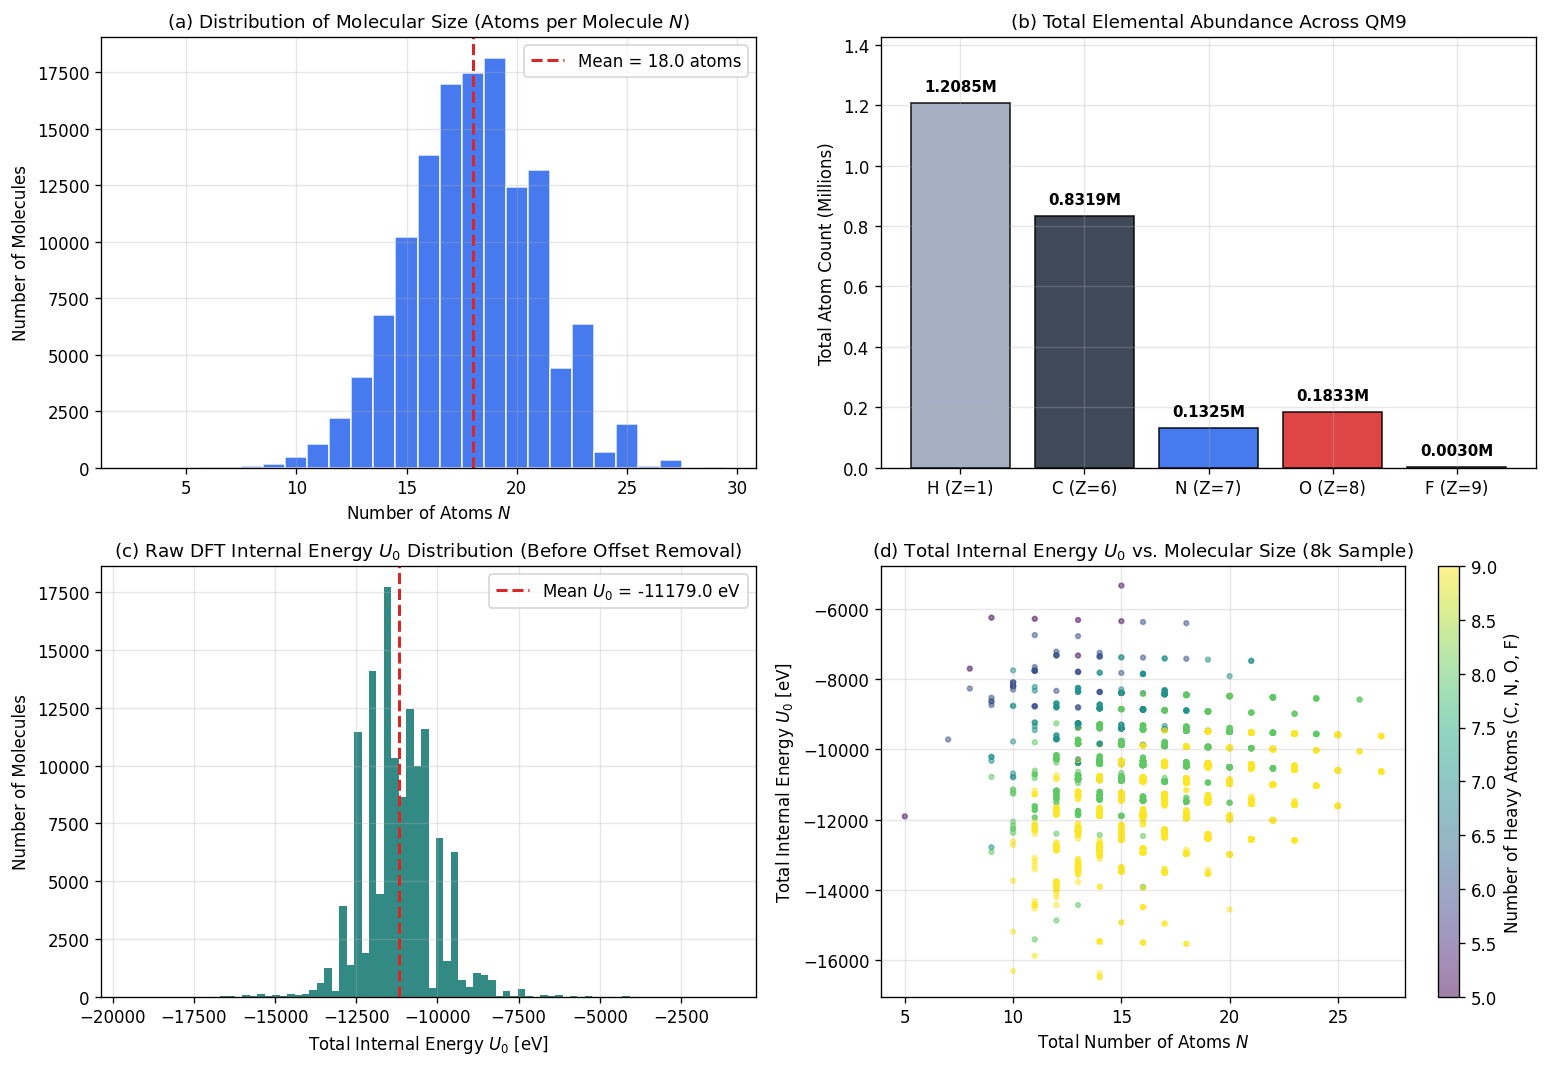

In [23]:
# Compute number of atoms per molecule from CSR pointer array
n_atoms_per_mol = (node_ptr[1:] - node_ptr[:-1]).numpy()
num_molecules = len(n_atoms_per_mol)

# Vectorized construction of the Stoichiometry Matrix A of shape (num_molecules, 5)
# Columns correspond to [count(H), count(C), count(N), count(O), count(F)]
mol_membership = torch.repeat_interleave(torch.arange(num_molecules), torch.from_numpy(n_atoms_per_mol))
stoichiometry_matrix = torch.zeros((num_molecules, 5), dtype=torch.float64)
for col_idx, atomic_num in enumerate(ATOMIC_NUMBERS_LIST):
    mask = (z_all.cpu() == atomic_num).to(torch.float64)
    # MUST use in-place index_add_ to modify stoichiometry_matrix in place!
    stoichiometry_matrix[:, col_idx].index_add_(0, mol_membership, mask)

element_totals = stoichiometry_matrix.sum(dim=0).numpy()

# Print summary table
print("=== QM9 Stoichiometric & Energetic Summary =")
print(f"Atoms per molecule (N) : min = {n_atoms_per_mol.min()}, median = {int(np.median(n_atoms_per_mol))}, "
      f"mean = {n_atoms_per_mol.mean():.2f}, max = {n_atoms_per_mol.max()}")
print(f"Raw U0 Energy [eV]     : min = {u0_all.min().item():.2f}, mean = {u0_all.mean().item():.2f}, "
      f"std = {u0_all.std().item():.2f}, max = {u0_all.max().item():.2f}")
for idx, z_val in enumerate(ATOMIC_NUMBERS_LIST):
    sym = ELEMENT_SYMBOLS[z_val]
    pct = 100.0 * element_totals[idx] / element_totals.sum()
    print(f"  Element {sym} (Z={z_val})      : {int(element_totals[idx]):>10,} atoms ({pct:5.2f}%)")

# --- FIGURE 1: 4-Panel Dataset Exploration ---
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Panel A: Molecular Size Distribution
bins_n = np.arange(n_atoms_per_mol.min() - 0.5, n_atoms_per_mol.max() + 1.5, 1.0)
axes[0, 0].hist(n_atoms_per_mol, bins=bins_n, color="#2563eb", edgecolor="white", alpha=0.85)
axes[0, 0].axvline(n_atoms_per_mol.mean(), color="#dc2626", linestyle="--", linewidth=1.8,
                   label=f"Mean = {n_atoms_per_mol.mean():.1f} atoms")
axes[0, 0].set_title("(a) Distribution of Molecular Size (Atoms per Molecule $N$)")
axes[0, 0].set_xlabel("Number of Atoms $N$")
axes[0, 0].set_ylabel("Number of Molecules")
axes[0, 0].legend()

# Panel B: Elemental Composition across QM9
labels_el = [f"{ELEMENT_SYMBOLS[z]} (Z={z})" for z in ATOMIC_NUMBERS_LIST]
colors_el = [ELEMENT_COLORS[z] for z in ATOMIC_NUMBERS_LIST]
bars = axes[0, 1].bar(labels_el, element_totals / 1e6, color=colors_el, edgecolor="black", alpha=0.85)
for bar, count in zip(bars, element_totals):
    # Changed formatting from :.2f to :.4f to preserve Fluorine's precision (0.0030M)
    axes[0, 1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.03,
                    f"{count/1e6:.4f}M", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0, 1].set_title("(b) Total Elemental Abundance Across QM9")
axes[0, 1].set_ylabel("Total Atom Count (Millions)")
axes[0, 1].set_ylim(0, max(element_totals / 1e6) * 1.18)

# Panel C: Raw Total Internal Energy U0 Histogram
u0_np = u0_all.numpy()
axes[1, 0].hist(u0_np, bins=80, color="#0f766e", edgecolor="none", alpha=0.85)
axes[1, 0].axvline(u0_np.mean(), color="#dc2626", linestyle="--", linewidth=1.8,
                   label=f"Mean $U_0$ = {u0_np.mean():.1f} eV")
axes[1, 0].set_title("(c) Raw DFT Internal Energy $U_0$ Distribution (Before Offset Removal)")
axes[1, 0].set_xlabel("Total Internal Energy $U_0$ [eV]")
axes[1, 0].set_ylabel("Number of Molecules")
axes[1, 0].legend()

# Panel D: Heavy Atom Count vs Total Energy U0
heavy_atoms_per_mol = stoichiometry_matrix[:, 1:].sum(dim=1).numpy()
sample_idx = np.random.choice(num_molecules, size=8000, replace=False)
sc = axes[1, 1].scatter(n_atoms_per_mol[sample_idx], u0_np[sample_idx],
                        c=heavy_atoms_per_mol[sample_idx], cmap="viridis", s=8, alpha=0.5)
cbar = plt.colorbar(sc, ax=axes[1, 1])
cbar.set_label("Number of Heavy Atoms (C, N, O, F)")
axes[1, 1].set_title("(d) Total Internal Energy $U_0$ vs. Molecular Size (8k Sample)")
axes[1, 1].set_xlabel("Total Number of Atoms $N$")
axes[1, 1].set_ylabel("Total Internal Energy $U_0$ [eV]")

plt.tight_layout()
plt.show()

## 5. Leak-Free Data Partitioning (80/10/10) and Empirical Linear Baseline (`Atomref`) Removal

### Why Single-Atom Offset Removal is Physically Essential
As observed in Figure 1(c)–(d), the total DFT internal energy $U_0$ spans more than $15,000\text{ eV}$ (with $\text{std}(U_0) \approx 1,087\text{ eV}$) because the core and valence electrons of isolated heavy atoms carry massive rest-state energies ($\approx -1030\text{ eV}$ per Carbon, $\approx -2042\text{ eV}$ per Oxygen), whereas the chemically relevant **interatomic interaction energy** varies by only a few electronvolts.

Instead of relying on external pre-tabulated reference files, we formulate baseline offset removal as an **empirical Ordinary Least Squares (OLS) linear model** fitted **exclusively on the Training Set** ($80\\%$ split) to prevent any data leakage into the Validation ($10\\%$) or Test ($10\\%$) partitions:

$$
E_{\mathrm{total}}^{(m)} = \sum_{Z \in \\{1,6,7,8,9\\}} A_{m, Z} \\, E_{\mathrm{atomref}}(Z) + \Delta U_0^{(m)}.
$$

Solving the overdetermined linear system $\mathbf{A}_{\mathrm{train}} \mathbf{e}_{\mathrm{atomref}} \approx \mathbf{u}_{0, \mathrm{train}}$ via SVD-based least squares (`torch.linalg.lstsq`) yields the optimal dressed atomic energies $\mathbf{e}_{\mathrm{atomref}} \in \mathbb{R}^5$. The neural network then learns the zero-centered **residual interaction energy** $\Delta U_0^{(m)} = U_0^{(m)} - \mathbf{A}_m \mathbf{e}_{\mathrm{atomref}}$, which has a standard deviation orders of magnitude smaller than raw $U_0$. During inference, the exact total energy is recovered via:

$$
\hat{U}_0^{(m)} = \hat{\Delta U}_0^{(m)} + \sum_{i=1}^{N_m} E_{\mathrm{atomref}}(Z_i).
$$

In [22]:
# 1. Deterministic 80% / 10% / 10% Split
gen = torch.Generator().manual_seed(SEED)
perm_indices = torch.randperm(num_molecules, generator=gen)

n_train = int(0.80 * num_molecules)  # 104,664 molecules
n_val   = int(0.10 * num_molecules)  # 13,083 molecules
n_test  = num_molecules - n_train - n_val  # 13,084 molecules

train_idx = perm_indices[:n_train]
val_idx   = perm_indices[n_train : n_train + n_val]
test_idx  = perm_indices[n_train + n_val :]

print("= Dataset Partitioning Summary (80 / 10 / 10) =")
print(f"Training Set   : {len(train_idx):>7,} molecules ({100*len(train_idx)/num_molecules:.1f}%)")
print(f"Validation Set : {len(val_idx):>7,} molecules ({100*len(val_idx)/num_molecules:.1f}%)")
print(f"Test Set       : {len(test_idx):>7,} molecules ({100*len(test_idx)/num_molecules:.1f}%)")
assert len(set(train_idx.tolist()).intersection(set(val_idx.tolist()))) == 0, "Leakage detected!"
assert len(set(train_idx.tolist()).intersection(set(test_idx.tolist()))) == 0, "Leakage detected!"

# 2. Fit Empirical OLS Atomic Reference Energies STRICTLY on the Training Split
A_train = stoichiometry_matrix[train_idx]  # (n_train, 5)
u0_train = u0_all[train_idx]               # (n_train,)

ols_solution = torch.linalg.lstsq(A_train, u0_train.unsqueeze(1))
empirical_atomrefs_5 = ols_solution.solution.squeeze(1)  # Shape: (5,)

# Build a fast lookup tensor indexed directly by atomic number Z (0..10)
atomref_lookup = torch.zeros(16, dtype=torch.float64)
for idx, z_val in enumerate(ATOMIC_NUMBERS_LIST):
    atomref_lookup[z_val] = empirical_atomrefs_5[idx]

# Compute baseline and residual interaction energies across all molecules
u0_baseline_all = stoichiometry_matrix @ empirical_atomrefs_5
u0_residual_all = (u0_all - u0_baseline_all).to(torch.float32)

# Compute per-atom residual statistics on the training set
train_residual = u0_residual_all[train_idx]
train_residual_per_atom = train_residual / torch.from_numpy(n_atoms_per_mol)[train_idx]

print("\n= Fitted Empirical OLS Single-Atom Reference Energies (Training Set) =")
for idx, z_val in enumerate(ATOMIC_NUMBERS_LIST):
    print(f"  E_atomref({ELEMENT_SYMBOLS[z_val]}, Z={z_val}) = {empirical_atomrefs_5[idx].item():12.6f} eV")

print("\n= Variance Reduction via Offset Removal (Training Set) =")
print(f"  Raw U0 Standard Deviation              : {u0_train.std().item():10.4f} eV")
print(f"  Residual Delta U0 Standard Deviation   : {train_residual.std().item():10.4f} eV")
print(f"  Mean Abs. Residual Target Error (MAE)  : {train_residual.abs().mean().item():10.4f} eV")

= Dataset Partitioning Summary (80 / 10 / 10) =
Training Set   : 104,664 molecules (80.0%)
Validation Set :  13,083 molecules (10.0%)
Test Set       :  13,084 molecules (10.0%)

= Fitted Empirical OLS Single-Atom Reference Energies (Training Set) =
  E_atomref(H, Z=1) =   -16.429628 eV
  E_atomref(C, Z=6) = -1036.047854 eV
  E_atomref(N, Z=7) = -1489.801173 eV
  E_atomref(O, Z=8) = -2046.984358 eV
  E_atomref(F, Z=9) = -2717.508318 eV

= Variance Reduction via Offset Removal (Training Set) =
  Raw U0 Standard Deviation              :  1085.7927 eV
  Residual Delta U0 Standard Deviation   :     1.0971 eV
  Mean Abs. Residual Target Error (MAE)  :     0.8666 eV


## 6. Custom Geometric Feature Engineering & Physical Visualizations

To feed our **Cartesian** $SO(3)$**-Equivariant Vector-Scalar GNN**, each molecule is transformed into a directed spatial radius graph with cutoff $r_c = 5.0\text{ \AA}$:
1. **Directed Radius Graph (**$\mathcal{E}$**):** All ordered pairs $(i, j)$ satisfying $0 < \\|\mathbf{r}_i - \mathbf{r}_j\\|_2 < r_c$.
2. **Scalar Interatomic Distance (**$d_{ij}$**):** $d_{ij} = \\|\mathbf{r}_i - \mathbf{r}_j\\|_2 \in (0, r_c)$.
3. **Equivariant Unit Direction Vector (**$\hat{\mathbf{u}}_{ij}$**):** $\hat{\mathbf{u}}_{ij} = \frac{\mathbf{r}_i - \mathbf{r}_j}{d_{ij}} \in \mathbb{R}^3$, satisfying $\\|\hat{\mathbf{u}}_{ij}\\|_2 = 1$.
4. **Smooth Gaussian Radial Basis Expansion (**$\mathbf{e}_{\mathrm{RBF}}(d_{ij})$**) with Cosine Cutoff Envelope:**
$$e_k(d_{ij}) = \exp\\!\Big(-\gamma (d_{ij} - \mu_k)^2\Big) \cdot \frac{1}{2}\left(\cos\\!\left(\frac{\pi d_{ij}}{r_c}\right) + 1\right), \quad k = 1, \dots, K.$$

Below, we implement these pure-PyTorch geometric modules and visualize the resulting physical distributions (radial pair distribution $g(d_{ij})$, covalent bond angle distribution $\theta_{jik}$ computed directly from unit-vector inner products $\hat{\mathbf{u}}_{ij} \cdot \hat{\mathbf{u}}_{ik}$, the smooth RBF filter bank, and a 3D molecular graph with equivariant unit vectors).

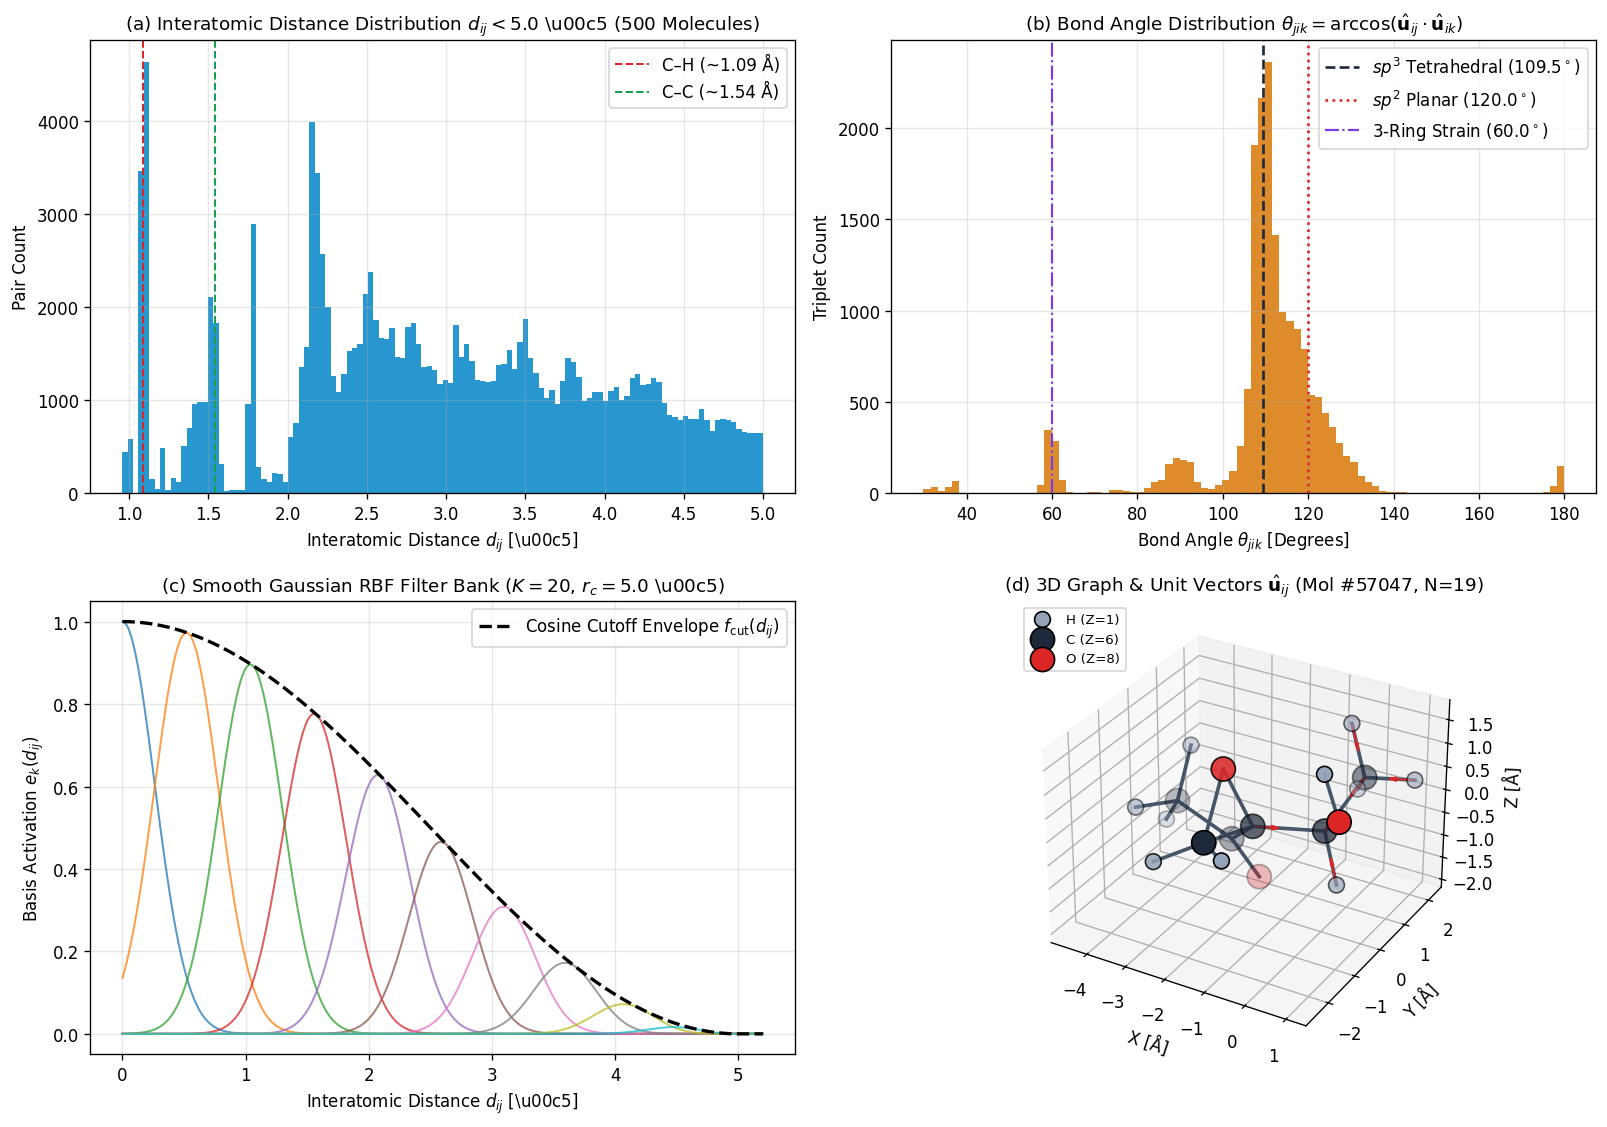

In [14]:
class SmoothGaussianRBF(nn.Module):
    """
    Expands scalar interatomic distances d_ij into K Gaussian Radial Basis Functions
    modulated by a C^infinity-smooth cosine cutoff envelope that vanishes at r_c.
    """
    def __init__(self, n_rbf: int = 20, cutoff: float = 5.0):
        super().__init__()
        self.n_rbf = n_rbf
        self.cutoff = float(cutoff)
        centers = torch.linspace(0.0, self.cutoff, n_rbf)
        widths = torch.full((n_rbf,), (centers[1] - centers[0]).item())
        gamma = 0.5 / (widths ** 2)
        self.register_buffer("centers", centers)
        self.register_buffer("gamma", gamma)

    def cosine_envelope(self, d: torch.Tensor) -> torch.Tensor:
        env = 0.5 * (torch.cos(math.pi * d / self.cutoff) + 1.0)
        return env * (d < self.cutoff).to(d.dtype)

    def forward(self, d: torch.Tensor) -> torch.Tensor:
        # d shape: (E, 1) -> returns (E, n_rbf)
        diff = d - self.centers.unsqueeze(0)
        rbf = torch.exp(-self.gamma.unsqueeze(0) * (diff ** 2))
        return rbf * self.cosine_envelope(d)


def build_equivariant_graph(
    pos: torch.Tensor,
    cutoff: float = 5.0,
) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """
    Constructs a directed radius graph from 3D coordinates `pos` of shape (N, 3).
    Returns:
        edge_index : (2, E) long tensor [row=target i, col=source j]
        edge_dist  : (E, 1) float32 scalar distances d_ij = ||r_i - r_j||_2
        edge_vec   : (E, 3) float32 unit direction vectors u_ij = (r_i - r_j) / d_ij
    """
    # Compute pairwise displacement vectors r_i - r_j of shape (N, N, 3)
    diff = pos.unsqueeze(1) - pos.unsqueeze(0)  # diff[i, j] = r_i - r_j
    dist_mat = torch.linalg.norm(diff, dim=-1)  # (N, N)

    # Mask out self-loops (d == 0) and pairs beyond cutoff r_c
    mask = (dist_mat > 1e-6) & (dist_mat < cutoff)
    edge_index = mask.nonzero(as_tuple=False).t().contiguous()  # (2, E)

    row, col = edge_index[0], edge_index[1]
    vec_ij = pos[row] - pos[col]                                # r_i - r_j: (E, 3)
    edge_dist = dist_mat[row, col].unsqueeze(1)                 # d_ij: (E, 1)
    edge_vec = vec_ij / edge_dist                               # u_ij: (E, 3)
    return edge_index, edge_dist, edge_vec


# --- Collect Geometric Statistics across 500 Training Molecules for Visualization ---
all_sample_dists = []
all_covalent_angles_deg = []
COVALENT_CUTOFF = 1.75  # Angstrom threshold for primary covalent bonds

for m_idx in train_idx[:500].tolist():
    s_start, s_end = node_ptr[m_idx].item(), node_ptr[m_idx + 1].item()
    pos_m = pos_all[s_start:s_end]
    e_idx, e_dist, e_vec = build_equivariant_graph(pos_m, cutoff=5.0)
    all_sample_dists.append(e_dist.squeeze(1).numpy())

    # Extract covalent bond angles around each central atom i using dot products u_ij . u_ik
    cov_mask = e_dist.squeeze(1) < COVALENT_CUTOFF
    cov_row = e_idx[0, cov_mask]
    cov_vec = e_vec[cov_mask]
    for center_atom in range(pos_m.size(0)):
        u_star = cov_vec[cov_row == center_atom]
        if u_star.size(0) >= 2:
            # Inner product matrix U U^T gives cos(theta_jik) for all neighbor pairs!
            cos_mat = torch.clamp(u_star @ u_star.t(), -1.0 + 1e-6, 1.0 - 1e-6)
            triu_idx = torch.triu_indices(u_star.size(0), u_star.size(0), offset=1)
            angles_deg = torch.rad2deg(torch.acos(cos_mat[triu_idx[0], triu_idx[1]])).numpy()
            all_covalent_angles_deg.append(angles_deg)

all_sample_dists = np.concatenate(all_sample_dists)
all_covalent_angles_deg = np.concatenate(all_covalent_angles_deg)

# --- FIGURE 3: 4-Panel Geometric & Equivariant Representation Analysis ---
fig = plt.figure(figsize=(13.5, 9.5))

# Panel A: Radial Pair Distribution Histogram
ax1 = fig.add_subplot(2, 2, 1)
ax1.hist(all_sample_dists, bins=120, color="#0284c7", edgecolor="none", alpha=0.85)
ax1.axvline(1.09, color="#dc2626", linestyle="--", linewidth=1.2, label="C–H (~1.09 \u00c5)")
ax1.axvline(1.54, color="#16a34a", linestyle="--", linewidth=1.2, label="C–C (~1.54 \u00c5)")
ax1.set_title(r"(a) Interatomic Distance Distribution $d_{ij} < 5.0$ \u00c5 (500 Molecules)")
ax1.set_xlabel(r"Interatomic Distance $d_{ij}$ [\u00c5]")
ax1.set_ylabel("Pair Count")
ax1.legend()

# Panel B: Covalent Bond Angle Distribution via Dot Products u_ij . u_ik
ax2 = fig.add_subplot(2, 2, 2)
ax2.hist(all_covalent_angles_deg, bins=90, color="#d97706", edgecolor="none", alpha=0.85)
ax2.axvline(109.47, color="#1e293b", linestyle="--", linewidth=1.6, label=r"$sp^3$ Tetrahedral ($109.5^\circ$)")
ax2.axvline(120.0, color="#dc2626", linestyle=":", linewidth=1.6, label=r"$sp^2$ Planar ($120.0^\circ$)")
ax2.axvline(60.0, color="#7c3aed", linestyle="-.", linewidth=1.3, label=r"3-Ring Strain ($60.0^\circ$)")
ax2.set_title(r"(b) Bond Angle Distribution $\theta_{jik} = \arccos(\hat{\mathbf{u}}_{ij} \cdot \hat{\mathbf{u}}_{ik})$")
ax2.set_xlabel(r"Bond Angle $\theta_{jik}$ [Degrees]")
ax2.set_ylabel("Triplet Count")
ax2.legend()

# Panel C: Smooth Gaussian RBF Filter Bank + Cosine Envelope
ax3 = fig.add_subplot(2, 2, 3)
rbf_layer = SmoothGaussianRBF(n_rbf=20, cutoff=5.0)
d_grid = torch.linspace(0.0, 5.2, 300).unsqueeze(1)
rbf_vals = rbf_layer(d_grid).numpy()
env_vals = rbf_layer.cosine_envelope(d_grid).numpy()
for k in range(0, 20, 2):
    ax3.plot(d_grid.numpy(), rbf_vals[:, k], alpha=0.75, linewidth=1.2)
ax3.plot(d_grid.numpy(), env_vals, "k--", linewidth=2.0, label=r"Cosine Cutoff Envelope $f_{\mathrm{cut}}(d_{ij})$")
ax3.set_title(r"(c) Smooth Gaussian RBF Filter Bank ($K=20$, $r_c = 5.0$ \u00c5)")
ax3.set_xlabel(r"Interatomic Distance $d_{ij}$ [\u00c5]")
ax3.set_ylabel(r"Basis Activation $e_k(d_{ij})$")
ax3.legend()

# Panel D: 3D Molecular Graph & Equivariant Unit Vector Field Render
ax4 = fig.add_subplot(2, 2, 4, projection="3d")
demo_mol_idx = train_idx[10].item()
s0, s1 = node_ptr[demo_mol_idx].item(), node_ptr[demo_mol_idx + 1].item()
pos_demo = pos_all[s0:s1].numpy()
z_demo = z_all[s0:s1].numpy()
e_idx_d, e_dist_d, e_vec_d = build_equivariant_graph(pos_all[s0:s1], cutoff=1.75)

# Plot covalent sticks and unit direction arrows from central atom 0
for edge_k in range(e_idx_d.size(1)):
    i_node, j_node = e_idx_d[0, edge_k].item(), e_idx_d[1, edge_k].item()
    if i_node < j_node:
        ax4.plot([pos_demo[i_node, 0], pos_demo[j_node, 0]],
                 [pos_demo[i_node, 1], pos_demo[j_node, 1]],
                 [pos_demo[i_node, 2], pos_demo[j_node, 2]], color="#475569", linewidth=2.2)

# Overlay equivariant unit vectors u_ij in red
for edge_k in range(min(8, e_idx_d.size(1))):
    i_node, j_node = e_idx_d[0, edge_k].item(), e_idx_d[1, edge_k].item()
    u_vec = e_vec_d[edge_k].numpy() * 0.55
    ax4.quiver(pos_demo[j_node, 0], pos_demo[j_node, 1], pos_demo[j_node, 2],
               u_vec[0], u_vec[1], u_vec[2], color="#dc2626", arrow_length_ratio=0.3, linewidth=1.2)

for unique_z in np.unique(z_demo):
    mask_z = (z_demo == unique_z)
    size_z = 90 if unique_z == 1 else 210
    ax4.scatter(pos_demo[mask_z, 0], pos_demo[mask_z, 1], pos_demo[mask_z, 2],
                s=size_z, color=ELEMENT_COLORS[int(unique_z)], edgecolors="black",
                depthshade=True, label=f"{ELEMENT_SYMBOLS[int(unique_z)]} (Z={unique_z})")

ax4.set_title(rf"(d) 3D Graph & Unit Vectors $\hat{{\mathbf{{u}}}}_{{ij}}$ (Mol #{demo_mol_idx}, N={len(z_demo)})")
ax4.set_xlabel("X [\u00c5]")
ax4.set_ylabel("Y [\u00c5]")
ax4.set_zlabel("Z [\u00c5]")
ax4.legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()


## 7. Sparse, Size-Independent Disjoint-Graph Batching Pipeline

A critical engineering requirement of our architecture is **strict size independence**: a model trained on QM9 molecules ($N \le 29$) must seamlessly accept macromolecules with hundreds or thousands of atoms ($N > 29$) without padding or weight changes.

### How Sparse Disjoint-Graph Batching Works
Instead of zero-padding coordinates to a fixed tensor shape $(B, N_{\max}, 3)$, our custom collation function (`collate_equivariant_graphs`) merges a batch of $B$ variable-sized molecular graphs $\\{\mathcal{G}_1, \dots, \mathcal{G}_B\\}$ into a single block-diagonal **disjoint super-graph** with $N_{\mathrm{total}} = \sum_{m=1}^B N_m$ nodes and $E_{\mathrm{total}} = \sum_{m=1}^B E_m$ directed edges:

1. **Cumulative Node Offset Shifting:** The edge indices of molecule $m$ are shifted by the cumulative atom count $\sum_{k=1}^{m-1} N_k$ so edge pointers address the correct atoms in the concatenated batch tensor.
2. **Graph Membership Vector (`batch`):** A 1D index tensor $\mathbf{b} \in \\{0, 1, \dots, B-1\\}^{N_{\mathrm{total}}}$ maps every atom $i$ to its parent molecule $m$ for the scatter-sum readout $\hat{U}_{0, m} = \sum_{i : b_i = m} \hat{\epsilon}_i$.
3. **Dynamic Atom-Budget Batch Sampler (`MaxAtomsBatchSampler`):** To guarantee bounded GPU memory consumption when scaling to large macromolecules ($N \gg 29$), our custom sampler dynamically groups molecules so that the **total number of atoms per mini-batch** never exceeds `max_atoms_per_batch` (e.g., $2,000\text{ atoms}$).

In [16]:
class EquivariantQM9Dataset(Dataset):
    """
    PyTorch Dataset serving individual molecular structures with precomputed
    OLS baseline energies, residual targets, and on-the-fly SO(3)-equivariant graph construction.
    """
    def __init__(
        self,
        mol_indices: torch.Tensor,
        z_all: torch.Tensor,
        pos_all: torch.Tensor,
        u0_raw_all: torch.Tensor,
        u0_baseline_all: torch.Tensor,
        u0_residual_all: torch.Tensor,
        node_ptr: torch.Tensor,
        cutoff: float = 5.0,
    ):
        super().__init__()
        self.mol_indices = mol_indices
        self.z_all = z_all
        self.pos_all = pos_all
        self.u0_raw_all = u0_raw_all
        self.u0_baseline_all = u0_baseline_all
        self.u0_residual_all = u0_residual_all
        self.node_ptr = node_ptr
        self.cutoff = float(cutoff)

        # Precompute atom counts per molecule in this split for dynamic atom-budget sampling
        self.atom_counts = (self.node_ptr[self.mol_indices + 1] - self.node_ptr[self.mol_indices]).tolist()

    def __len__(self) -> int:
        return len(self.mol_indices)

    def __getitem__(self, idx: int) -> Dict[str, torch.Tensor]:
        m_id = self.mol_indices[idx].item()
        start, end = self.node_ptr[m_id].item(), self.node_ptr[m_id + 1].item()

        z = self.z_all[start:end]          # (N_m,) int64
        pos = self.pos_all[start:end]      # (N_m, 3) float32
        edge_index, edge_dist, edge_vec = build_equivariant_graph(pos, cutoff=self.cutoff)

        return {
            "mol_id": torch.tensor([m_id], dtype=torch.long),
            "z": z,
            "pos": pos,
            "edge_index": edge_index,      # (2, E_m) int64
            "edge_dist": edge_dist,        # (E_m, 1) float32
            "edge_vec": edge_vec,          # (E_m, 3) float32
            "y_residual": self.u0_residual_all[m_id].view(1),            # (1,) float32 [eV]
            "y_atomref": self.u0_baseline_all[m_id].to(torch.float32).view(1),  # (1,) float32 [eV]
            "y_raw": self.u0_raw_all[m_id].to(torch.float32).view(1),    # (1,) float32 [eV]
        }


def collate_equivariant_graphs(samples: List[Dict[str, torch.Tensor]]) -> Dict[str, torch.Tensor]:
    """
    Sparse, size-independent disjoint-graph collation function.
    Concatenates arbitrary-sized molecules without padding.
    """
    z_list, pos_list = [], []
    edge_index_list, edge_dist_list, edge_vec_list = [], [], []
    batch_list, n_atoms_list = [], []
    mol_id_list, y_res_list, y_ref_list, y_raw_list = [], [], [], []

    cum_nodes = 0
    for batch_idx, item in enumerate(samples):
        num_nodes = item["z"].size(0)
        z_list.append(item["z"])
        pos_list.append(item["pos"])
        # Offset edge indices by the cumulative number of atoms in previous molecules
        edge_index_list.append(item["edge_index"] + cum_nodes)
        edge_dist_list.append(item["edge_dist"])
        edge_vec_list.append(item["edge_vec"])

        batch_list.append(torch.full((num_nodes,), batch_idx, dtype=torch.long))
        n_atoms_list.append(num_nodes)
        mol_id_list.append(item["mol_id"])
        y_res_list.append(item["y_residual"])
        y_ref_list.append(item["y_atomref"])
        y_raw_list.append(item["y_raw"])

        cum_nodes += num_nodes

    return {
        "mol_id": torch.cat(mol_id_list, dim=0),            # (B,)
        "z": torch.cat(z_list, dim=0),                      # (N_total,)
        "pos": torch.cat(pos_list, dim=0),                  # (N_total, 3)
        "edge_index": torch.cat(edge_index_list, dim=1),    # (2, E_total)
        "edge_dist": torch.cat(edge_dist_list, dim=0),      # (E_total, 1)
        "edge_vec": torch.cat(edge_vec_list, dim=0),        # (E_total, 3)
        "batch": torch.cat(batch_list, dim=0),              # (N_total,)
        "n_atoms": torch.tensor(n_atoms_list, dtype=torch.long),  # (B,)
        "y_residual": torch.cat(y_res_list, dim=0),         # (B,)
        "y_atomref": torch.cat(y_ref_list, dim=0),          # (B,)
        "y_raw": torch.cat(y_raw_list, dim=0),              # (B,)
    }


class MaxAtomsBatchSampler(Sampler[List[int]]):
    """
    Dynamic Atom-Budget Sampler: caps the total number of atoms per mini-batch
    (`max_atoms`) and optional maximum molecule count (`max_molecules`) so that
    both small QM9 molecules and 1,000+ atom macromolecules maintain bounded VRAM.
    """
    def __init__(
        self,
        atom_counts: List[int],
        max_atoms: int = 1800,
        max_molecules: int = 100,
        shuffle: bool = True,
        seed: int = 42,
    ):
        self.atom_counts = atom_counts
        self.max_atoms = max_atoms
        self.max_molecules = max_molecules
        self.shuffle = shuffle
        self.seed = seed
        self.epoch = 0

    def __iter__(self):
        indices = list(range(len(self.atom_counts)))
        if self.shuffle:
            rng = random.Random(self.seed + self.epoch)
            rng.shuffle(indices)
        self.epoch += 1

        current_batch = []
        current_atoms = 0
        for idx in indices:
            n_at = self.atom_counts[idx]
            if current_batch and (
                current_atoms + n_at > self.max_atoms or len(current_batch) >= self.max_molecules
            ):
                yield current_batch
                current_batch = []
                current_atoms = 0
            current_batch.append(idx)
            current_atoms += n_at
        if current_batch:
            yield current_batch

    def __len__(self) -> int:
        avg_atoms = sum(self.atom_counts) / max(1, len(self.atom_counts))
        eff_bs = min(self.max_molecules, max(1, int(self.max_atoms / avg_atoms)))
        return math.ceil(len(self.atom_counts) / eff_bs)


## 8. Final Verification: Prepared Training, Validation & Test Inputs/Outputs, $SO(3)$ Equivariance Proof, and Macromolecular ($N > 29$) Scalability Test

In this final section, we instantiate the Training, Validation, and Test `DataLoader` pipelines and perform three rigorous engineering checks:
1. **Live Batch Tensor Inspection:** Verify exact input (`z`, `pos`, `edge_index`, `edge_dist`, `edge_vec`, `batch`) and output (`y_residual`, `y_atomref`, `y_raw`) shapes and dtypes across all three splits.
2. **Exact** $SO(3)$ **Rotation Invariance & Equivariance Proof:** Apply a random 3D orthogonal rotation matrix $\mathbf{Q} \in SO(3)$ ($\det(\mathbf{Q}) = +1$) to a molecular batch and verify that distances remain invariant ($\Vert{}\mathbf{d}' - \mathbf{d}\Vert{}_\infty < 10^{-5}$) while unit direction vectors rotate covariantly ($\Vert{}\hat{\mathbf{u}}' - \hat{\mathbf{u}}\mathbf{Q}^\top\Vert{}_\infty < 10^{-5}$).
3. **Macromolecular (**$N = 150 > 29$**) Co-Batching Proof:** Construct a synthetic $150$-atom macromolecule, co-batch it alongside standard QM9 molecules ($N \le 29$), and pass the combined sparse disjoint graph through a prototype Cartesian $SO(3)$-Equivariant Vector-Scalar interaction block to prove seamless size-independent execution.

In [18]:
# 1. Instantiate Train, Validation, and Test Datasets and Sparse DataLoaders
CUTOFF_RADIUS = 5.0

train_dataset = EquivariantQM9Dataset(
    train_idx, z_all, pos_all, u0_all, u0_baseline_all, u0_residual_all, node_ptr, cutoff=CUTOFF_RADIUS
)
val_dataset = EquivariantQM9Dataset(
    val_idx, z_all, pos_all, u0_all, u0_baseline_all, u0_residual_all, node_ptr, cutoff=CUTOFF_RADIUS
)
test_dataset = EquivariantQM9Dataset(
    test_idx, z_all, pos_all, u0_all, u0_baseline_all, u0_residual_all, node_ptr, cutoff=CUTOFF_RADIUS
)

train_sampler = MaxAtomsBatchSampler(train_dataset.atom_counts, max_atoms=1800, max_molecules=100, shuffle=True, seed=SEED)
val_sampler   = MaxAtomsBatchSampler(val_dataset.atom_counts,   max_atoms=1800, max_molecules=100, shuffle=False, seed=SEED)
test_sampler  = MaxAtomsBatchSampler(test_dataset.atom_counts,  max_atoms=1800, max_molecules=100, shuffle=False, seed=SEED)

train_loader = DataLoader(train_dataset, batch_sampler=train_sampler, collate_fn=collate_equivariant_graphs)
val_loader   = DataLoader(val_dataset,   batch_sampler=val_sampler,   collate_fn=collate_equivariant_graphs)
test_loader  = DataLoader(test_dataset,  batch_sampler=test_sampler,  collate_fn=collate_equivariant_graphs)

# Fetch one live batch from each split
train_batch = next(iter(train_loader))
val_batch   = next(iter(val_loader))
test_batch  = next(iter(test_loader))

print("= Prepared DataLoader Verification (Train / Val / Test Splits) =")
for split_name, b in [("TRAIN", train_batch), ("VAL  ", val_batch), ("TEST ", test_batch)]:
    print(f"[{split_name}] Molecules B = {b['mol_id'].numel():3d} | "
          f"Total Atoms N_tot = {b['z'].numel():4d} | "
          f"Directed Edges E_tot = {b['edge_dist'].size(0):5d} | "
          f"Target y_residual shape = {tuple(b['y_residual'].shape)}")

print("\n= Detailed Tensor Schema of a Prepared Training Batch =")
for key, tensor in train_batch.items():
    role = "OUTPUT TARGET" if key.startswith("y_") else "INPUT FEATURE"
    print(f"  {role:13s} | {key:12s} : shape = {str(tuple(tensor.shape)):16s} | dtype = {tensor.dtype}")

# 2. Exact SO(3) Rotation Invariance & Equivariance Numerical Test
random_mat = torch.randn(3, 3)
Q_rot, _ = torch.linalg.qr(random_mat)
if torch.linalg.det(Q_rot) < 0:
    Q_rot[:, 0] = -Q_rot[:, 0]  # Ensure proper rotation matrix in SO(3) with det(Q) = +1

pos_orig = train_batch["pos"][:train_batch["n_atoms"][0]]
pos_rot  = pos_orig @ Q_rot.t()  # Rotate coordinates: r' = Q r

_, dist_orig, vec_orig = build_equivariant_graph(pos_orig, cutoff=CUTOFF_RADIUS)
_, dist_rot,  vec_rot  = build_equivariant_graph(pos_rot,  cutoff=CUTOFF_RADIUS)

dist_invariance_err = torch.max(torch.abs(dist_rot - dist_orig)).item()
vec_equivariance_err = torch.max(torch.abs(vec_rot - (vec_orig @ Q_rot.t()))).item()

print("\n= Mathematical SO(3) Symmetry Verification =")
print(f"  Max Scalar Distance Invariance Error  ||d(Qr) - d(r)||_inf       : {dist_invariance_err:.3e} A")
print(f"  Max Vector Direction Equivariance Err ||u(Qr) - Q u(r)||_inf     : {vec_equivariance_err:.3e}")
assert dist_invariance_err < 1e-5 and vec_equivariance_err < 1e-5, "SO(3) symmetry check failed!"

# 3. Macromolecular (N = 150 > 29) Co-Batching & Equivariant Block Forward Proof
class PrototypeEquivariantVectorScalarBlock(nn.Module):
    """Minimal Cartesian SO(3)-Equivariant Vector-Scalar layer verifying size-independent execution."""
    def __init__(self, hidden_dim: int = 64, n_rbf: int = 20, cutoff: float = 5.0):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.embedding = nn.Embedding(16, hidden_dim)
        self.rbf = SmoothGaussianRBF(n_rbf=n_rbf, cutoff=cutoff)
        self.filter_net = nn.Linear(n_rbf, 2 * hidden_dim)
        self.U1 = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.U2 = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.readout = nn.Sequential(nn.Linear(2 * hidden_dim, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, 1))

    def forward(self, batch_dict: Dict[str, torch.Tensor]) -> torch.Tensor:
        z = batch_dict["z"]
        row, col = batch_dict["edge_index"][0], batch_dict["edge_index"][1]
        d_ij, u_ij = batch_dict["edge_dist"], batch_dict["edge_vec"]
        batch_idx = batch_dict["batch"]

        s = self.embedding(z)                                    # Invariant scalars: (N_tot, F)
        v = torch.zeros(z.size(0), self.hidden_dim, 3, device=z.device)  # Equivariant vectors: (N_tot, F, 3)

        # Message passing from source j (col) to target i (row)
        w_s, w_v = self.filter_net(self.rbf(d_ij)).chunk(2, dim=-1)
        msg_s = s[col] * w_s                                     # (E_tot, F)
        msg_v = (s[col] * w_v).unsqueeze(-1) * u_ij.unsqueeze(1) # (E_tot, F, 3)

        s.index_add_(0, row, msg_s)
        v.index_add_(0, row, msg_v)

        # Equivariant inner product <U1 v, U2 v> recovers 3-body cos(theta_jik) angles
        v_t = v.transpose(1, 2)                                  # (N_tot, 3, F)
        v1 = self.U1(v_t).transpose(1, 2)                        # (N_tot, F, 3)
        v2 = self.U2(v_t).transpose(1, 2)                        # (N_tot, F, 3)
        angular_dots = torch.sum(v1 * v2, dim=-1)                # Invariant dot products: (N_tot, F)

        atom_energies = self.readout(torch.cat([s, angular_dots], dim=-1)).squeeze(-1)  # (N_tot,)
        mol_energies = torch.zeros(batch_dict["mol_id"].size(0), device=z.device)
        mol_energies.index_add_(0, batch_idx, atom_energies)
        return mol_energies + batch_dict["y_atomref"]

# Create a synthetic 150-atom macromolecule and co-batch it with two QM9 molecules
N_macro = 150
pos_macro = torch.randn(N_macro, 3) * 3.5
z_macro = torch.tensor([6, 1, 1, 7, 8] * (N_macro // 5), dtype=torch.long)
e_idx_m, e_dist_m, e_vec_m = build_equivariant_graph(pos_macro, cutoff=CUTOFF_RADIUS)
macro_sample = {
    "mol_id": torch.tensor([999999], dtype=torch.long),
    "z": z_macro,
    "pos": pos_macro,
    "edge_index": e_idx_m,
    "edge_dist": e_dist_m,
    "edge_vec": e_vec_m,
    "y_residual": torch.tensor([0.0]),
    "y_atomref": atomref_lookup[z_macro].sum().to(torch.float32).view(1),
    "y_raw": atomref_lookup[z_macro].sum().to(torch.float32).view(1),
}

mixed_batch = collate_equivariant_graphs([train_dataset[0], train_dataset[1], macro_sample])
proto_model = PrototypeEquivariantVectorScalarBlock(hidden_dim=64, n_rbf=20, cutoff=CUTOFF_RADIUS)
with torch.no_grad():
    pred_u0 = proto_model(mixed_batch)

print("\n= Macromolecular Scalability Verification (Co-Batching N <= 29 with N = 150) ===")
print(f"  Mixed Batch Atom Counts n_atoms : {mixed_batch['n_atoms'].tolist()} (Total = {mixed_batch['z'].numel()} atoms)")
print(f"  Mixed Batch Predicted U0 Shape  : {tuple(pred_u0.shape)} -> Values: {pred_u0.tolist()}")
print("  SUCCESS: Milestone 1 data pipeline and sparse equivariant batching verified!")

= Prepared DataLoader Verification (Train / Val / Test Splits) =
[TRAIN] Molecules B =  97 | Total Atoms N_tot = 1789 | Directed Edges E_tot = 28378 | Target y_residual shape = (97,)
[VAL  ] Molecules B =  99 | Total Atoms N_tot = 1794 | Directed Edges E_tot = 27832 | Target y_residual shape = (99,)
[TEST ] Molecules B = 100 | Total Atoms N_tot = 1780 | Directed Edges E_tot = 27474 | Target y_residual shape = (100,)

= Detailed Tensor Schema of a Prepared Training Batch =
  INPUT FEATURE | mol_id       : shape = (97,)            | dtype = torch.int64
  INPUT FEATURE | z            : shape = (1789,)          | dtype = torch.int64
  INPUT FEATURE | pos          : shape = (1789, 3)        | dtype = torch.float32
  INPUT FEATURE | edge_index   : shape = (2, 28378)       | dtype = torch.int64
  INPUT FEATURE | edge_dist    : shape = (28378, 1)       | dtype = torch.float32
  INPUT FEATURE | edge_vec     : shape = (28378, 3)       | dtype = torch.float32
  INPUT FEATURE | batch        : shap